In [1]:
from pathlib import Path
import pandas as pd

# Locate the repository root
current = Path.cwd()

ROOT = next(
    (
        folder
        for folder in [current, *current.parents]
        if (folder / ".git").exists()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Could not locate the project root."
    )

# Locate the previously downloaded MovieLens ratings file
RATINGS_PATH = (
    ROOT
    / "task-01-collaborative-filtering"
    / "data"
    / "ml-100k"
    / "u.data"
)

if not RATINGS_PATH.exists():
    raise FileNotFoundError(
        f"MovieLens data not found at: {RATINGS_PATH}"
    )

ratings_df = pd.read_csv(
    RATINGS_PATH,
    sep="\t",
    header=None,
    names=["user_id", "movie_id", "rating", "timestamp"]
)

print("Dataset shape:", ratings_df.shape)
print("Unique users:", ratings_df["user_id"].nunique())
print("Unique movies:", ratings_df["movie_id"].nunique())

Dataset shape: (100000, 4)
Unique users: 943
Unique movies: 1682


In [2]:
from sklearn.model_selection import train_test_split

# First, separate 80% training data from 20% held-out data
train_df, remaining_df = train_test_split(
    ratings_df,
    test_size=0.20,
    random_state=42,
    stratify=ratings_df["rating"]
)

# Divide the remaining 20% equally into validation and test sets
val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=42,
    stratify=remaining_df["rating"]
)

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

Training rows: 80000
Validation rows: 10000
Test rows: 10000


In [3]:
print("Original dataset:", len(ratings_df))
print("Total after splitting:",
      len(train_df) + len(val_df) + len(test_df))

# Verify that no original record occurs in multiple sets
train_ids = set(train_df.index)
val_ids = set(val_df.index)
test_ids = set(test_df.index)

print("\nTraining-validation overlap:",
      len(train_ids & val_ids))

print("Training-test overlap:",
      len(train_ids & test_ids))

print("Validation-test overlap:",
      len(val_ids & test_ids))

Original dataset: 100000
Total after splitting: 100000

Training-validation overlap: 0
Training-test overlap: 0
Validation-test overlap: 0


In [4]:
# Build the matrix using TRAINING data only
train_matrix = train_df.pivot(
    index="user_id",
    columns="movie_id",
    values="rating"
)

print("Training matrix shape:", train_matrix.shape)

print("\nFirst 5 users and 10 movies:")
display(train_matrix.iloc[:5, :10])

Training matrix shape: (943, 1652)

First 5 users and 10 movies:


movie_id,1,2,3,4,5,6,7,8,9,10
user_id,,,,,,,,,,
1,5.0,NaN,4.0,3.0,3.0,5.0,4.0,1.0,5.0,NaN
2,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Count ratings available to the model
observed_ratings = train_matrix.notna().sum().sum()

# Count every possible user-movie combination
total_possible = (
    train_matrix.shape[0] * train_matrix.shape[1]
)

# Calculate the percentage of missing combinations
sparsity = (
    1 - observed_ratings / total_possible
) * 100

print("Training users:", train_matrix.shape[0])
print("Training movies:", train_matrix.shape[1])
print("Observed training ratings:", observed_ratings)
print("Possible combinations:", total_possible)
print(f"Training matrix sparsity: {sparsity:.2f}%")

Training users: 943
Training movies: 1652
Observed training ratings: 80000
Possible combinations: 1557836
Training matrix sparsity: 94.86%


In [6]:
# Calculate each user's average rating using training data only
user_means = train_matrix.mean(axis=1)

# Subtract each user's average from their observed ratings
centered_matrix = train_matrix.sub(user_means, axis=0)

print("Original ratings:")
display(train_matrix.iloc[:5, :10])

print("\nMean-centered ratings:")
display(centered_matrix.iloc[:5, :10])

Original ratings:


movie_id,1,2,3,4,5,6,7,8,9,10
user_id,,,,,,,,,,
1,5.0,NaN,4.0,3.0,3.0,5.0,4.0,1.0,5.0,NaN
2,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Mean-centered ratings:


movie_id,1,2,3,4,5,6,7,8,9,10
user_id,,,,,,,,,,
1,1.340807,NaN,0.340807,-0.659193,-0.659193,1.340807,0.340807,-2.659193,1.340807,NaN
2,0.285714,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,1.097015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
from sklearn.metrics.pairwise import cosine_similarity

# Represent missing centered ratings as zero contributions
centered_filled = centered_matrix.fillna(0.0)

# Calculate similarity between every pair of users
similarity_array = cosine_similarity(centered_filled)

# Store the results in a labelled DataFrame
user_similarity = pd.DataFrame(
    similarity_array,
    index=train_matrix.index,
    columns=train_matrix.index
)

print("Similarity matrix shape:", user_similarity.shape)

# Display a small portion
display(user_similarity.iloc[:5, :5])

Similarity matrix shape: (943, 943)


user_id,1,2,3,4,5
user_id,,,,,
1,1.000000,0.016065,-0.000436,0.060864,0.100890
2,0.016065,1.000000,0.012091,-0.059482,0.007509
3,-0.000436,0.012091,1.000000,-0.047094,0.022916
4,0.060864,-0.059482,-0.047094,1.000000,-0.001765
5,0.100890,0.007509,0.022916,-0.001765,1.000000


In [8]:
# Get similarities between User 1 and every other user
similar_users = user_similarity.loc[1].drop(index=1)

# Sort from most similar to least similar
top_neighbors = similar_users.sort_values(
    ascending=False
).head(10)

display(
    top_neighbors.rename_axis("neighbor_user_id")
    .reset_index(name="similarity")
)

,neighbor_user_id,similarity
0,806,0.198851
1,276,0.174017
2,246,0.173468
3,550,0.172875
4,868,0.167050
5,62,0.162966
6,738,0.161925
7,413,0.161093
8,303,0.156612
9,592,0.149592


In [9]:
import numpy as np

# Calculate the global average using training data only
global_mean = train_df["rating"].mean()


def predict_rating(user_id, movie_id, k=20):
    """
    Predict a movie rating using user-based collaborative filtering.
    Uses training data and precomputed user similarities only.
    """

    # Handle a user not present in the training matrix
    if user_id not in train_matrix.index:
        return float(global_mean)

    # Our baseline prediction is the target user's mean rating
    user_mean = float(user_means.loc[user_id])

    # Handle a movie absent from the training matrix
    if movie_id not in train_matrix.columns:
        return float(np.clip(user_mean, 1, 5))

    # Find users who rated this movie in the training data
    movie_ratings = train_matrix[movie_id].dropna()
    movie_ratings = movie_ratings.drop(
        index=user_id,
        errors="ignore"
    )

    if movie_ratings.empty:
        return float(np.clip(user_mean, 1, 5))

    # Get similarities between the target user
    # and users who rated this movie
    similarities = user_similarity.loc[user_id].reindex(
        movie_ratings.index
    )

    # Keep only positive similarities
    similarities = similarities[similarities > 0]

    if similarities.empty:
        return float(np.clip(user_mean, 1, 5))

    # Select the k most similar eligible neighbours
    top_similarities = similarities.nlargest(k)
    neighbor_ids = top_similarities.index

    # Calculate neighbours' deviations from their own means
    deviations = centered_matrix.loc[
        neighbor_ids, movie_id
    ].to_numpy()

    weights = top_similarities.to_numpy()

    # Add the weighted average deviation to the target user's mean
    prediction = user_mean + (
        np.dot(weights, deviations) / weights.sum()
    )

    # MovieLens ratings range from 1 to 5
    return float(np.clip(prediction, 1, 5))


print("Prediction function defined successfully!")

Prediction function defined successfully!


In [10]:
# Choose one validation rating for a movie seen in training
eligible_validation = val_df[
    val_df["movie_id"].isin(train_matrix.columns)
]

sample = eligible_validation.iloc[0]

user_id = int(sample["user_id"])
movie_id = int(sample["movie_id"])
actual_rating = float(sample["rating"])

predicted_rating = predict_rating(
    user_id,
    movie_id,
    k=20
)

print("User ID:", user_id)
print("Movie ID:", movie_id)
print("Actual rating:", actual_rating)
print("Predicted rating:", round(predicted_rating, 3))
print(
    "Absolute error:",
    round(abs(actual_rating - predicted_rating), 3)
)

User ID: 804
Movie ID: 393
Actual rating: 3.0
Predicted rating: 3.951
Absolute error: 0.951


In [11]:
actual_rating = float(sample["rating"])
predicted_rating = predict_rating(
    int(sample["user_id"]),
    int(sample["movie_id"]),
    k=20
)

error = actual_rating - predicted_rating

print(f"Actual rating: {actual_rating:.2f}")
print(f"Predicted rating: {predicted_rating:.2f}")
print(f"Absolute error: {abs(error):.2f}")
print(f"Squared error: {error**2:.2f}")

Actual rating: 3.00
Predicted rating: 3.95
Absolute error: 0.95
Squared error: 0.90


In [12]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Convert the existing training data and similarities to arrays
train_values = train_matrix.to_numpy(dtype=float)
centered_values = centered_matrix.to_numpy(dtype=float)
similarity_values = user_similarity.to_numpy(dtype=float)

# Map user and movie IDs to array positions
user_to_pos = {
    int(user_id): pos
    for pos, user_id in enumerate(train_matrix.index)
}

movie_to_pos = {
    int(movie_id): pos
    for pos, movie_id in enumerate(train_matrix.columns)
}

user_mean_values = user_means.reindex(
    train_matrix.index
).to_numpy(dtype=float)

user_mean_lookup = {
    int(user_id): float(mean)
    for user_id, mean in user_means.items()
}

global_mean = float(train_df["rating"].mean())


def evaluate_user_cf(eval_df, k=20):
    """Predict ratings using training data and evaluate on eval_df."""

    y_true = eval_df["rating"].to_numpy(dtype=float)
    y_pred = np.empty(len(eval_df))
    fallback_count = 0

    for i, row in enumerate(eval_df.itertuples(index=False)):
        user_id = int(row.user_id)
        movie_id = int(row.movie_id)

        user_pos = user_to_pos.get(user_id)
        movie_pos = movie_to_pos.get(movie_id)

        # Unknown users fall back to the global mean
        if user_pos is None:
            y_pred[i] = global_mean
            fallback_count += 1
            continue

        user_mean = user_mean_values[user_pos]

        # Movies absent from training fall back to user mean
        if movie_pos is None:
            y_pred[i] = user_mean
            fallback_count += 1
            continue

        # Find training users who rated this movie
        neighbor_positions = np.flatnonzero(
            np.isfinite(train_values[:, movie_pos])
        )

        # Exclude the target user
        neighbor_positions = neighbor_positions[
            neighbor_positions != user_pos
        ]

        # Obtain similarities with eligible neighbors
        scores = similarity_values[
            user_pos, neighbor_positions
        ]

        # Retain positive similarities only
        positive = scores > 0
        neighbor_positions = neighbor_positions[positive]
        scores = scores[positive]

        if len(scores) == 0:
            y_pred[i] = user_mean
            fallback_count += 1
            continue

        # Select up to k most similar neighbors
        n_neighbors = min(k, len(scores))

        if len(scores) > n_neighbors:
            selected = np.argpartition(
                scores, -n_neighbors
            )[-n_neighbors:]
        else:
            selected = np.arange(len(scores))

        neighbors = neighbor_positions[selected]
        weights = scores[selected]

        # Weighted average of neighbors' centered ratings
        deviations = centered_values[
            neighbors, movie_pos
        ]

        prediction = user_mean + (
            np.dot(weights, deviations) / weights.sum()
        )

        # Keep predictions within the known rating scale
        y_pred[i] = np.clip(prediction, 1, 5)

    return y_true, y_pred, fallback_count


# Evaluate using k = 20
y_true, cf_predictions, fallback_count = evaluate_user_cf(
    val_df,
    k=20
)

# Baseline: predict each user's mean training rating
baseline_predictions = np.array([
    user_mean_lookup.get(int(user_id), global_mean)
    for user_id in val_df["user_id"]
])

baseline_predictions = np.clip(
    baseline_predictions, 1, 5
)

# Compare both approaches
print("Validation records:", len(y_true))
print("CF fallback predictions:", fallback_count)

print("\nBaseline — User Mean")
print(
    "MAE:",
    round(mean_absolute_error(y_true, baseline_predictions), 4)
)
print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_true, baseline_predictions)), 4)
)

print("\nUser-based Collaborative Filtering — k=20")
print(
    "MAE:",
    round(mean_absolute_error(y_true, cf_predictions), 4)
)
print(
    "RMSE:",
    round(np.sqrt(mean_squared_error(y_true, cf_predictions)), 4)
)

Validation records: 10000
CF fallback predictions: 27

Baseline — User Mean
MAE: 0.8386
RMSE: 1.0457

User-based Collaborative Filtering — k=20
MAE: 0.7383
RMSE: 0.9451


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

k_values = [5, 10, 20, 40, 80]
results = []

for k in k_values:
    y_true_k, predictions_k, fallback_count = evaluate_user_cf(
        val_df,
        k=k
    )

    mae = mean_absolute_error(y_true_k, predictions_k)
    rmse = np.sqrt(
        mean_squared_error(y_true_k, predictions_k)
    )

    results.append({
        "k": k,
        "MAE": mae,
        "RMSE": rmse,
        "Fallback predictions": fallback_count
    })

results_df = pd.DataFrame(results)

display(
    results_df.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}"
    })
)

# Select k using validation RMSE
best_row = results_df.loc[results_df["RMSE"].idxmin()]

best_k = int(best_row["k"])

print("Best k by validation RMSE:", best_k)
print(f"Best validation RMSE: {best_row['RMSE']:.4f}")
print(f"Corresponding MAE: {best_row['MAE']:.4f}")

,k,MAE,RMSE,Fallback predictions
0,5,0.7668,0.9849,27
1,10,0.7458,0.9556,27
2,20,0.7383,0.9451,27
3,40,0.7387,0.9450,27
4,80,0.7409,0.9473,27


Best k by validation RMSE: 40
Best validation RMSE: 0.9450
Corresponding MAE: 0.7387


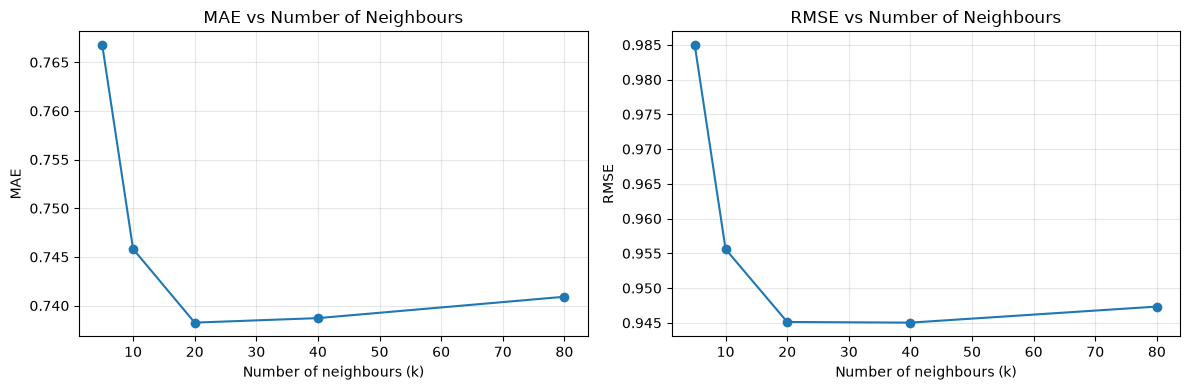

Results saved to: C:\Users\91636\recommender-systems-from-scratch\task-01-collaborative-filtering\results
Figure saved to: C:\Users\91636\recommender-systems-from-scratch\task-01-collaborative-filtering\figures


In [14]:
import matplotlib.pyplot as plt

# Create output folders
RESULTS_DIR = ROOT / "task-01-collaborative-filtering" / "results"
FIGURES_DIR = ROOT / "task-01-collaborative-filtering" / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Save the numerical results
results_df.to_csv(
    RESULTS_DIR / "user_cf_neighborhood_comparison.csv",
    index=False
)

# Plot MAE and RMSE against the number of neighbours
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(results_df["k"], results_df["MAE"], marker="o")
axes[0].set_title("MAE vs Number of Neighbours")
axes[0].set_xlabel("Number of neighbours (k)")
axes[0].set_ylabel("MAE")
axes[0].grid(True, alpha=0.3)

axes[1].plot(results_df["k"], results_df["RMSE"], marker="o")
axes[1].set_title("RMSE vs Number of Neighbours")
axes[1].set_xlabel("Number of neighbours (k)")
axes[1].set_ylabel("RMSE")
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "user_cf_neighborhood_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Results saved to:", RESULTS_DIR)
print("Figure saved to:", FIGURES_DIR)

In [15]:
import numpy as np

# Make the experiment reproducible
np.random.seed(42)

# Global average computed from training ratings only
global_mean_mf = float(train_df["rating"].mean())

# Map original user IDs and movie IDs to array positions
user_ids = np.sort(train_df["user_id"].unique())
movie_ids = np.sort(train_df["movie_id"].unique())

user_to_idx = {
    int(user_id): idx
    for idx, user_id in enumerate(user_ids)
}

movie_to_idx = {
    int(movie_id): idx
    for idx, movie_id in enumerate(movie_ids)
}

# Convert training records into compact numerical arrays
train_user_idx = train_df["user_id"].map(user_to_idx).to_numpy()
train_movie_idx = train_df["movie_id"].map(movie_to_idx).to_numpy()
train_ratings = train_df["rating"].to_numpy(dtype=np.float64)

print("Training users:", len(user_ids))
print("Training movies:", len(movie_ids))
print("Training interactions:", len(train_ratings))
print("Global training mean:", round(global_mean_mf, 4))

Training users: 943
Training movies: 1652
Training interactions: 80000
Global training mean: 3.5299


In [16]:
# Matrix factorization configuration
n_factors = 32
learning_rate = 0.01
regularization = 0.02
n_epochs = 20

# Use a reproducible random generator
rng = np.random.default_rng(42)

# Number of users and movies in training
n_users = len(user_ids)
n_movies = len(movie_ids)

# Initialize user and movie latent-factor matrices
P = rng.normal(
    loc=0.0,
    scale=0.1,
    size=(n_users, n_factors)
)

Q = rng.normal(
    loc=0.0,
    scale=0.1,
    size=(n_movies, n_factors)
)

# Initialize user and movie biases
user_bias = np.zeros(n_users)
movie_bias = np.zeros(n_movies)

print("User factor matrix:", P.shape)
print("Movie factor matrix:", Q.shape)
print("User bias vector:", user_bias.shape)
print("Movie bias vector:", movie_bias.shape)

User factor matrix: (943, 32)
Movie factor matrix: (1652, 32)
User bias vector: (943,)
Movie bias vector: (1652,)


In [20]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Keep the values we initialized earlier.
# n_factors = 32
# learning_rate = 0.01
# regularization = 0.02
# n_epochs = 20

shuffle_rng = np.random.default_rng(42)

history = []

for epoch in range(n_epochs):

    # Shuffle training examples for this epoch
    order = shuffle_rng.permutation(len(train_ratings))

    # Learn from one rating at a time
    for idx in order:
        u = train_user_idx[idx]
        i = train_movie_idx[idx]
        actual = train_ratings[idx]

        # Current prediction
        prediction = (
            global_mean_mf
            + user_bias[u]
            + movie_bias[i]
            + np.dot(P[u], Q[i])
        )

        error = actual - prediction

        # Preserve the original vectors for both updates
        p_old = P[u].copy()
        q_old = Q[i].copy()

        # Update biases
        user_bias[u] += learning_rate * (
            error - regularization * user_bias[u]
        )

        movie_bias[i] += learning_rate * (
            error - regularization * movie_bias[i]
        )

        # Update latent factor vectors
        P[u] += learning_rate * (
            error * q_old - regularization * p_old
        )

        Q[i] += learning_rate * (
            error * p_old - regularization * q_old
        )

    # Calculate training RMSE after the epoch
    train_predictions = (
        global_mean_mf
        + user_bias[train_user_idx]
        + movie_bias[train_movie_idx]
        + np.sum(
            P[train_user_idx] * Q[train_movie_idx],
            axis=1
        )
    )

    train_rmse = np.sqrt(
        np.mean((train_ratings - train_predictions) ** 2)
    )

    # Evaluate on validation data without updating parameters
    val_user_idx = (
        val_df["user_id"]
        .map(user_to_idx)
        .fillna(-1)
        .astype(int)
        .to_numpy()
    )
    
    val_movie_idx = (
        val_df["movie_id"]
        .map(movie_to_idx)
        .fillna(-1)
        .astype(int)
        .to_numpy()
    )

    actual_val = val_df["rating"].to_numpy(dtype=float)
    val_predictions = np.full(
        len(val_df), global_mean_mf, dtype=float
    )

    known_users = val_user_idx >= 0
    known_movies = val_movie_idx >= 0
    both_known = known_users & known_movies

    # Unknown users fall back to the global mean.
    # Known users with unknown movies use their user bias.
    val_predictions[known_users & ~known_movies] += (
        user_bias[val_user_idx[known_users & ~known_movies]]
    )

    # Known movies with unknown users use their movie bias.
    val_predictions[~known_users & known_movies] += (
        movie_bias[val_movie_idx[~known_users & known_movies]]
    )

    # Predict normally when both IDs appeared in training
    u = val_user_idx[both_known]
    i = val_movie_idx[both_known]

    val_predictions[both_known] = (
        global_mean_mf
        + user_bias[u]
        + movie_bias[i]
        + np.sum(P[u] * Q[i], axis=1)
    )

    # Respect the 1–5 rating scale for evaluation
    val_predictions = np.clip(val_predictions, 1, 5)

    val_rmse = np.sqrt(
        mean_squared_error(actual_val, val_predictions)
    )
    val_mae = mean_absolute_error(
        actual_val, val_predictions
    )

    history.append({
        "epoch": epoch + 1,
        "train_RMSE": train_rmse,
        "val_RMSE": val_rmse,
        "val_MAE": val_mae
    })

    print(
        f"Epoch {epoch + 1:02d}/{n_epochs} | "
        f"Train RMSE: {train_rmse:.4f} | "
        f"Val RMSE: {val_rmse:.4f} | "
        f"Val MAE: {val_mae:.4f}"
    )

history_df = pd.DataFrame(history)

Epoch 01/20 | Train RMSE: 0.9323 | Val RMSE: 0.9719 | Val MAE: 0.7714
Epoch 02/20 | Train RMSE: 0.9170 | Val RMSE: 0.9637 | Val MAE: 0.7629
Epoch 03/20 | Train RMSE: 0.9054 | Val RMSE: 0.9587 | Val MAE: 0.7577
Epoch 04/20 | Train RMSE: 0.8949 | Val RMSE: 0.9553 | Val MAE: 0.7548
Epoch 05/20 | Train RMSE: 0.8836 | Val RMSE: 0.9525 | Val MAE: 0.7524
Epoch 06/20 | Train RMSE: 0.8707 | Val RMSE: 0.9504 | Val MAE: 0.7495
Epoch 07/20 | Train RMSE: 0.8557 | Val RMSE: 0.9473 | Val MAE: 0.7464
Epoch 08/20 | Train RMSE: 0.8386 | Val RMSE: 0.9445 | Val MAE: 0.7445
Epoch 09/20 | Train RMSE: 0.8199 | Val RMSE: 0.9422 | Val MAE: 0.7425
Epoch 10/20 | Train RMSE: 0.7998 | Val RMSE: 0.9396 | Val MAE: 0.7393
Epoch 11/20 | Train RMSE: 0.7794 | Val RMSE: 0.9392 | Val MAE: 0.7385
Epoch 12/20 | Train RMSE: 0.7587 | Val RMSE: 0.9389 | Val MAE: 0.7374
Epoch 13/20 | Train RMSE: 0.7384 | Val RMSE: 0.9394 | Val MAE: 0.7379
Epoch 14/20 | Train RMSE: 0.7189 | Val RMSE: 0.9412 | Val MAE: 0.7388
Epoch 15/20 | Train 

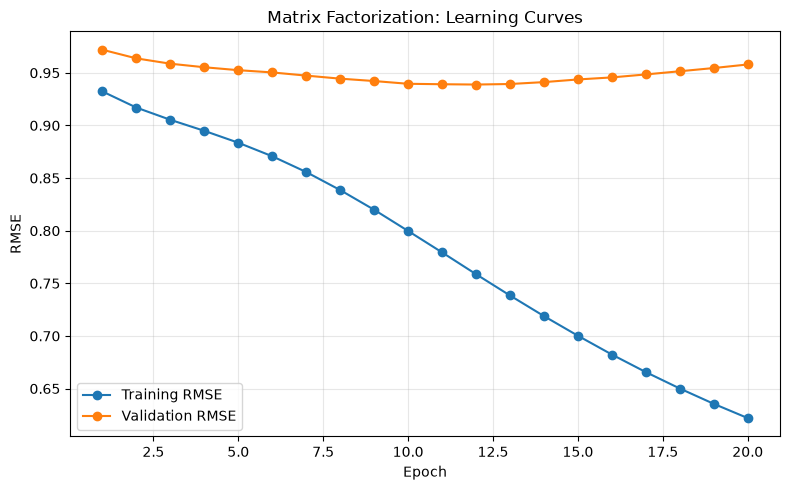

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    history_df["epoch"],
    history_df["val_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.title("Matrix Factorization: Learning Curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Training configuration
learning_rate = 0.01
regularization = 0.02
max_epochs = 30
patience = 4

shuffle_rng = np.random.default_rng(42)

# Convert validation IDs to training-array positions.
# Use -1 for IDs that do not occur in training.
val_user_idx = (
    val_df["user_id"]
    .map(user_to_idx)
    .fillna(-1)
    .astype(int)
    .to_numpy()
)

val_movie_idx = (
    val_df["movie_id"]
    .map(movie_to_idx)
    .fillna(-1)
    .astype(int)
    .to_numpy()
)

actual_val = val_df["rating"].to_numpy(dtype=float)

known_users = val_user_idx >= 0
known_movies = val_movie_idx >= 0
both_known = known_users & known_movies

def predict_validation_mf():
    """Predict validation ratings without updating model parameters."""

    predictions = np.full(
        len(val_df), global_mean_mf, dtype=float
    )

    # Known user, unknown movie: use global mean + user bias
    mask = known_users & ~known_movies
    predictions[mask] += user_bias[val_user_idx[mask]]

    # Unknown user, known movie: use global mean + movie bias
    mask = ~known_users & known_movies
    predictions[mask] += movie_bias[val_movie_idx[mask]]

    # Both user and movie known: use the full model
    u = val_user_idx[both_known]
    i = val_movie_idx[both_known]

    predictions[both_known] = (
        global_mean_mf
        + user_bias[u]
        + movie_bias[i]
        + np.sum(P[u] * Q[i], axis=1)
    )

    return np.clip(predictions, 1, 5)


# Early-stopping state
best_val_rmse = float("inf")
best_epoch = 0
best_state = None
epochs_without_improvement = 0
history = []

for epoch in range(max_epochs):

    # Shuffle the training ratings
    order = shuffle_rng.permutation(len(train_ratings))

    for idx in order:
        u = train_user_idx[idx]
        i = train_movie_idx[idx]
        actual = train_ratings[idx]

        prediction = (
            global_mean_mf
            + user_bias[u]
            + movie_bias[i]
            + np.dot(P[u], Q[i])
        )

        error = actual - prediction

        # Preserve the original vectors for both updates
        p_old = P[u].copy()
        q_old = Q[i].copy()

        # Update biases
        user_bias[u] += learning_rate * (
            error - regularization * user_bias[u]
        )

        movie_bias[i] += learning_rate * (
            error - regularization * movie_bias[i]
        )

        # Update latent factors
        P[u] += learning_rate * (
            error * q_old - regularization * p_old
        )

        Q[i] += learning_rate * (
            error * p_old - regularization * q_old
        )

    # Evaluate training predictions
    train_predictions = (
        global_mean_mf
        + user_bias[train_user_idx]
        + movie_bias[train_movie_idx]
        + np.sum(
            P[train_user_idx] * Q[train_movie_idx],
            axis=1
        )
    )

    train_rmse = np.sqrt(
        mean_squared_error(train_ratings, train_predictions)
    )

    # Evaluate validation predictions
    val_predictions = predict_validation_mf()

    val_rmse = np.sqrt(
        mean_squared_error(actual_val, val_predictions)
    )

    val_mae = mean_absolute_error(
        actual_val, val_predictions
    )

    history.append({
        "epoch": epoch + 1,
        "train_RMSE": train_rmse,
        "val_RMSE": val_rmse,
        "val_MAE": val_mae
    })

    print(
        f"Epoch {epoch + 1:02d} | "
        f"Train RMSE: {train_rmse:.4f} | "
        f"Val RMSE: {val_rmse:.4f} | "
        f"Val MAE: {val_mae:.4f}"
    )

    # Save the parameters whenever validation RMSE improves
    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        best_epoch = epoch + 1

        best_state = (
            P.copy(),
            Q.copy(),
            user_bias.copy(),
            movie_bias.copy()
        )

        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Stop when validation has not improved for four epochs
    if epochs_without_improvement >= patience:
        print(
            f"\nEarly stopping at epoch {epoch + 1}. "
            f"Best epoch was {best_epoch}."
        )
        break


# Restore the best validation checkpoint
P, Q, user_bias, movie_bias = [
    arr.copy() for arr in best_state
]

history_df = pd.DataFrame(history)

best_row = history_df.loc[
    history_df["val_RMSE"].idxmin()
]

print("\nBest model restored.")
print("Best epoch:", best_epoch)
print(f"Best validation RMSE: {best_row['val_RMSE']:.4f}")
print(f"Validation MAE: {best_row['val_MAE']:.4f}")

Epoch 01 | Train RMSE: 0.6094 | Val RMSE: 0.9614 | Val MAE: 0.7525
Epoch 02 | Train RMSE: 0.5977 | Val RMSE: 0.9650 | Val MAE: 0.7542
Epoch 03 | Train RMSE: 0.5869 | Val RMSE: 0.9677 | Val MAE: 0.7561
Epoch 04 | Train RMSE: 0.5770 | Val RMSE: 0.9709 | Val MAE: 0.7582
Epoch 05 | Train RMSE: 0.5676 | Val RMSE: 0.9737 | Val MAE: 0.7599

Early stopping at epoch 5. Best epoch was 1.

Best model restored.
Best epoch: 1
Best validation RMSE: 0.9614
Validation MAE: 0.7525


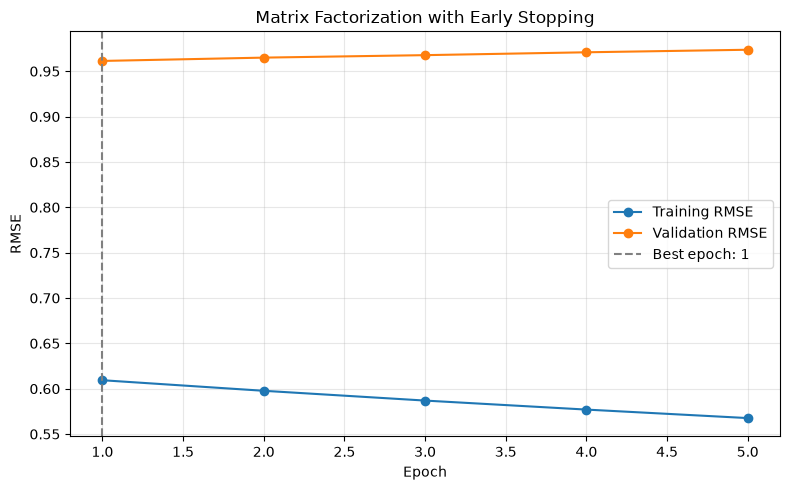

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    history_df["epoch"],
    history_df["val_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.title("Matrix Factorization with Early Stopping")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

# ============================================================
# 1. CONFIGURATION
# ============================================================

n_factors = 32
learning_rate = 0.01
regularization = 0.02
max_epochs = 30
patience = 4
random_seed = 42

# ============================================================
# 2. PREPARE TRAINING DATA AND ID MAPPINGS
# ============================================================

global_mean_mf = float(train_df["rating"].mean())

user_ids = np.sort(train_df["user_id"].unique())
movie_ids = np.sort(train_df["movie_id"].unique())

user_to_idx = {
    int(uid): idx for idx, uid in enumerate(user_ids)
}

movie_to_idx = {
    int(mid): idx for idx, mid in enumerate(movie_ids)
}

n_users = len(user_ids)
n_movies = len(movie_ids)

train_user_idx = (
    train_df["user_id"].map(user_to_idx).to_numpy(dtype=int)
)
train_movie_idx = (
    train_df["movie_id"].map(movie_to_idx).to_numpy(dtype=int)
)
train_ratings = train_df["rating"].to_numpy(dtype=float)

# Map validation IDs. -1 marks entities absent from training.
val_user_idx = (
    val_df["user_id"].map(user_to_idx)
    .fillna(-1).astype(int).to_numpy()
)
val_movie_idx = (
    val_df["movie_id"].map(movie_to_idx)
    .fillna(-1).astype(int).to_numpy()
)

actual_val = val_df["rating"].to_numpy(dtype=float)

known_users = val_user_idx >= 0
known_movies = val_movie_idx >= 0
both_known = known_users & known_movies

# ============================================================
# 3. INITIALIZE A FRESH MODEL
# ============================================================

rng = np.random.default_rng(random_seed)

P = rng.normal(
    0.0, 0.1, size=(n_users, n_factors)
)
Q = rng.normal(
    0.0, 0.1, size=(n_movies, n_factors)
)

user_bias = np.zeros(n_users)
movie_bias = np.zeros(n_movies)

print("Fresh model initialized.")
print("User factors:", P.shape)
print("Movie factors:", Q.shape)

# ============================================================
# 4. VALIDATION PREDICTION FUNCTION
# ============================================================

def predict_validation_mf():
    predictions = np.full(
        len(val_df), global_mean_mf, dtype=float
    )

    # Known user, unknown movie
    mask = known_users & ~known_movies
    predictions[mask] += user_bias[val_user_idx[mask]]

    # Unknown user, known movie
    mask = ~known_users & known_movies
    predictions[mask] += movie_bias[val_movie_idx[mask]]

    # Both entities known: use the full model
    u = val_user_idx[both_known]
    i = val_movie_idx[both_known]

    predictions[both_known] = (
        global_mean_mf
        + user_bias[u]
        + movie_bias[i]
        + np.sum(P[u] * Q[i], axis=1)
    )

    return np.clip(predictions, 1, 5)


# ============================================================
# 5. TRAIN WITH STOCHASTIC GRADIENT DESCENT
# ============================================================

shuffle_rng = np.random.default_rng(random_seed)

history = []
best_val_rmse = float("inf")
best_epoch = 0
best_state = None
epochs_without_improvement = 0

for epoch in range(1, max_epochs + 1):

    # Randomize the order of training ratings
    order = shuffle_rng.permutation(len(train_ratings))

    for idx in order:
        u = train_user_idx[idx]
        i = train_movie_idx[idx]
        actual = train_ratings[idx]

        prediction = (
            global_mean_mf
            + user_bias[u]
            + movie_bias[i]
            + np.dot(P[u], Q[i])
        )

        error = actual - prediction

        # Save original vectors for simultaneous factor updates
        p_old = P[u].copy()
        q_old = Q[i].copy()

        # Update user and movie biases
        user_bias[u] += learning_rate * (
            error - regularization * user_bias[u]
        )
        movie_bias[i] += learning_rate * (
            error - regularization * movie_bias[i]
        )

        # Update latent factors
        P[u] += learning_rate * (
            error * q_old - regularization * p_old
        )
        Q[i] += learning_rate * (
            error * p_old - regularization * q_old
        )

    # Training RMSE
    train_predictions = (
        global_mean_mf
        + user_bias[train_user_idx]
        + movie_bias[train_movie_idx]
        + np.sum(
            P[train_user_idx] * Q[train_movie_idx],
            axis=1
        )
    )

    train_rmse = np.sqrt(
        mean_squared_error(train_ratings, train_predictions)
    )

    # Validation metrics: no parameter updates on validation data
    val_predictions = predict_validation_mf()

    val_rmse = np.sqrt(
        mean_squared_error(actual_val, val_predictions)
    )
    val_mae = mean_absolute_error(actual_val, val_predictions)

    history.append({
        "epoch": epoch,
        "train_RMSE": train_rmse,
        "val_RMSE": val_rmse,
        "val_MAE": val_mae
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train RMSE: {train_rmse:.4f} | "
        f"Val RMSE: {val_rmse:.4f} | "
        f"Val MAE: {val_mae:.4f}"
    )

    # Save the best model according to validation RMSE
    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        best_epoch = epoch

        best_state = (
            P.copy(),
            Q.copy(),
            user_bias.copy(),
            movie_bias.copy()
        )

        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Stop after patience epochs without improvement
    if epochs_without_improvement >= patience:
        print(f"\nEarly stopping at epoch {epoch}.")
        break

# ============================================================
# 6. RESTORE THE BEST CHECKPOINT
# ============================================================

P, Q, user_bias, movie_bias = [
    array.copy() for array in best_state
]

history_df = pd.DataFrame(history)

best_row = history_df.loc[
    history_df["val_RMSE"].idxmin()
]

print("\nTraining complete.")
print("Best epoch:", best_epoch)
print(f"Best validation RMSE: {best_row['val_RMSE']:.4f}")
print(f"Validation MAE at best epoch: {best_row['val_MAE']:.4f}")

Fresh model initialized.
User factors: (943, 32)
Movie factors: (1652, 32)
Epoch 01 | Train RMSE: 0.9605 | Val RMSE: 0.9902 | Val MAE: 0.7910
Epoch 02 | Train RMSE: 0.9323 | Val RMSE: 0.9718 | Val MAE: 0.7708
Epoch 03 | Train RMSE: 0.9169 | Val RMSE: 0.9634 | Val MAE: 0.7623
Epoch 04 | Train RMSE: 0.9055 | Val RMSE: 0.9586 | Val MAE: 0.7580
Epoch 05 | Train RMSE: 0.8948 | Val RMSE: 0.9552 | Val MAE: 0.7551
Epoch 06 | Train RMSE: 0.8835 | Val RMSE: 0.9530 | Val MAE: 0.7522
Epoch 07 | Train RMSE: 0.8707 | Val RMSE: 0.9501 | Val MAE: 0.7492
Epoch 08 | Train RMSE: 0.8558 | Val RMSE: 0.9473 | Val MAE: 0.7471
Epoch 09 | Train RMSE: 0.8388 | Val RMSE: 0.9448 | Val MAE: 0.7450
Epoch 10 | Train RMSE: 0.8198 | Val RMSE: 0.9414 | Val MAE: 0.7412
Epoch 11 | Train RMSE: 0.8000 | Val RMSE: 0.9402 | Val MAE: 0.7397
Epoch 12 | Train RMSE: 0.7793 | Val RMSE: 0.9390 | Val MAE: 0.7378
Epoch 13 | Train RMSE: 0.7587 | Val RMSE: 0.9386 | Val MAE: 0.7377
Epoch 14 | Train RMSE: 0.7385 | Val RMSE: 0.9397 | Val

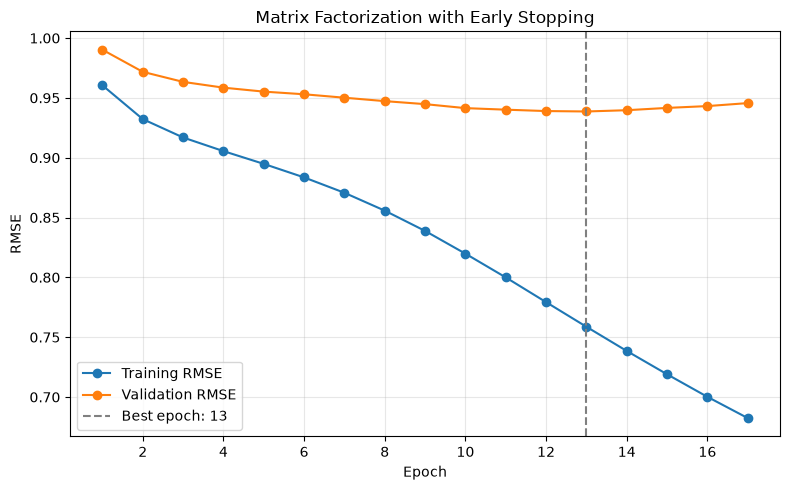

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    history_df["epoch"],
    history_df["val_RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.title("Matrix Factorization with Early Stopping")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict using the restored, best matrix-factorization checkpoint.
# This function handles users or movies not observed during training.
def predict_mf_for_df(eval_df):
    u_idx = (
        eval_df["user_id"]
        .map(user_to_idx)
        .fillna(-1)
        .astype(int)
        .to_numpy()
    )

    i_idx = (
        eval_df["movie_id"]
        .map(movie_to_idx)
        .fillna(-1)
        .astype(int)
        .to_numpy()
    )

    known_u = u_idx >= 0
    known_i = i_idx >= 0
    both = known_u & known_i

    predictions = np.full(
        len(eval_df), global_mean_mf, dtype=float
    )

    # Known user, unseen movie
    mask = known_u & ~known_i
    predictions[mask] += user_bias[u_idx[mask]]

    # Unseen user, known movie
    mask = ~known_u & known_i
    predictions[mask] += movie_bias[i_idx[mask]]

    # Both user and movie known
    u = u_idx[both]
    i = i_idx[both]

    predictions[both] = (
        global_mean_mf
        + user_bias[u]
        + movie_bias[i]
        + np.sum(P[u] * Q[i], axis=1)
    )

    return np.clip(predictions, 1, 5)


# These settings have already been selected using validation data.
selected_k = 40

test_actual, cf_test_pred, cf_fallbacks = evaluate_user_cf(
    test_df, k=selected_k
)

mf_test_pred = predict_mf_for_df(test_df)

# User-mean baseline for comparison
user_mean_lookup = {
    int(uid): float(mean)
    for uid, mean in user_means.items()
}

test_baseline_pred = np.array([
    user_mean_lookup.get(int(uid), global_mean_mf)
    for uid in test_df["user_id"]
])

test_baseline_pred = np.clip(test_baseline_pred, 1, 5)


def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        )
    }


# Compare selected models on the untouched test set
test_results = pd.DataFrame([
    {
        "Model": "User-mean baseline",
        **calculate_metrics(test_actual, test_baseline_pred)
    },
    {
        "Model": f"User-based CF (k={selected_k})",
        **calculate_metrics(test_actual, cf_test_pred)
    },
    {
        "Model": f"Matrix factorization (epoch {best_epoch})",
        **calculate_metrics(test_actual, mf_test_pred)
    }
])

display(test_results.round(4))

print("Test ratings:", len(test_df))
print("CF fallback predictions:", cf_fallbacks)

,Model,MAE,RMSE
0,User-mean baseline,0.8348,1.0412
1,User-based CF (k=40),0.7219,0.9254
2,Matrix factorization (epoch 13),0.7290,0.9265


Test ratings: 10000
CF fallback predictions: 22


In [27]:
import pandas as pd
from pathlib import Path

movies_path = (
    ROOT
    / "task-01-collaborative-filtering"
    / "data"
    / "ml-100k"
    / "u.item"
)

movies_df = pd.read_csv(
    movies_path,
    sep="|",
    header=None,
    usecols=[0, 1],
    names=["movie_id", "title"],
    encoding="latin-1"
)

print("Movie titles loaded:", len(movies_df))
display(movies_df.head())

Movie titles loaded: 1682


,movie_id,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


In [28]:
import numpy as np

target_user_id = 1

if target_user_id not in user_to_idx:
    raise ValueError("This user does not occur in the training data.")

# Only exclude movies that the user rated in the training set.
# Validation and test ratings remain hidden from our recommender.
rated_movies = set(
    train_df.loc[
        train_df["user_id"] == target_user_id,
        "movie_id"
    ]
)

candidate_movies = [
    int(movie_id)
    for movie_id in movie_ids
    if int(movie_id) not in rated_movies
]

user_idx = user_to_idx[target_user_id]

candidate_indices = np.array(
    [movie_to_idx[mid] for mid in candidate_movies],
    dtype=int
)

# Vectorized matrix-factorization predictions
mf_scores = (
    global_mean_mf
    + user_bias[user_idx]
    + movie_bias[candidate_indices]
    + Q[candidate_indices] @ P[user_idx]
)

mf_scores = np.clip(mf_scores, 1, 5)

mf_recommendations = pd.DataFrame({
    "movie_id": candidate_movies,
    "predicted_rating": mf_scores
})

mf_recommendations["title"] = (
    mf_recommendations["movie_id"]
    .map(movies_df.drop_duplicates("movie_id")
         .set_index("movie_id")["title"])
)

mf_recommendations = (
    mf_recommendations
    .dropna(subset=["title"])
    .sort_values("predicted_rating", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

mf_recommendations.index = mf_recommendations.index + 1
mf_recommendations.index.name = "Rank"

display(mf_recommendations[["movie_id", "title", "predicted_rating"]].round({
    "predicted_rating": 3
}))

,movie_id,title,predicted_rating
Rank,,,
1,652,Rosencrantz and Guildenstern Are Dead (1990),4.827
2,408,"Close Shave, A (1995)",4.817
3,251,Shall We Dance? (1996),4.799
4,475,Trainspotting (1996),4.781
5,100,Fargo (1996),4.655
6,430,Duck Soup (1933),4.648
7,276,Leaving Las Vegas (1995),4.642
8,89,Blade Runner (1982),4.587
9,285,Secrets & Lies (1996),4.577


In [29]:
selected_k = 40

cf_scores = [
    predict_rating(target_user_id, movie_id, k=selected_k)
    for movie_id in candidate_movies
]

cf_recommendations = pd.DataFrame({
    "movie_id": candidate_movies,
    "predicted_rating": cf_scores
})

cf_recommendations["title"] = (
    cf_recommendations["movie_id"]
    .map(movies_df.drop_duplicates("movie_id")
         .set_index("movie_id")["title"])
)

cf_recommendations = (
    cf_recommendations
    .dropna(subset=["title"])
    .sort_values("predicted_rating", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

cf_recommendations.index = cf_recommendations.index + 1
cf_recommendations.index.name = "Rank"

display(cf_recommendations[["movie_id", "title", "predicted_rating"]].round({
    "predicted_rating": 3
}))

,movie_id,title,predicted_rating
Rank,,,
1,1554,Safe Passage (1994),5.000
2,1599,Someone Else's America (1995),5.000
3,1467,"Saint of Fort Washington, The (1993)",5.000
4,814,"Great Day in Harlem, A (1994)",5.000
5,1080,Celestial Clockwork (1994),4.998
6,1449,Pather Panchali (1955),4.967
7,64,"Shawshank Redemption, The (1994)",4.873
8,1642,Some Mother's Son (1996),4.859
9,1398,Anna (1996),4.850


In [30]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the final test comparison
test_results.to_csv(
    RESULTS_DIR / "final_test_comparison.csv",
    index=False
)

# Save the matrix-factorization learning history
history_df.to_csv(
    RESULTS_DIR / "matrix_factorization_training.csv",
    index=False
)

# Save both recommendation lists
mf_recommendations.to_csv(
    RESULTS_DIR / "example_recommendations_matrix_factorization.csv",
    index=True
)

cf_recommendations.to_csv(
    RESULTS_DIR / "example_recommendations_user_cf.csv",
    index=True
)

print("Task 1 outputs saved in:", RESULTS_DIR)

Task 1 outputs saved in: C:\Users\91636\recommender-systems-from-scratch\task-01-collaborative-filtering\results


In [31]:
# Examine how much training data supports our recommendations

movie_support = (
    train_df.groupby("movie_id")["rating"]
    .agg(
        training_rating_count="count",
        training_mean_rating="mean"
    )
    .reset_index()
)

# Add support information to matrix-factorization recommendations
mf_audit = mf_recommendations.merge(
    movie_support,
    on="movie_id",
    how="left"
)

print("Matrix Factorization Recommendations")
display(
    mf_audit[
        [
            "title",
            "predicted_rating",
            "training_rating_count",
            "training_mean_rating"
        ]
    ].round(3)
)

# Add support information to collaborative-filtering recommendations
cf_audit = cf_recommendations.merge(
    movie_support,
    on="movie_id",
    how="left"
)

print("User-based Collaborative Filtering Recommendations")
display(
    cf_audit[
        [
            "title",
            "predicted_rating",
            "training_rating_count",
            "training_mean_rating"
        ]
    ].round(3)
)

Matrix Factorization Recommendations


,title,predicted_rating,training_rating_count,training_mean_rating
0,Rosencrantz and Guildenstern Are Dead (1990),4.827,68,3.897
1,"Close Shave, A (1995)",4.817,92,4.446
2,Shall We Dance? (1996),4.799,32,4.312
3,Trainspotting (1996),4.781,203,3.941
4,Fargo (1996),4.655,393,4.137
5,Duck Soup (1933),4.648,80,3.988
6,Leaving Las Vegas (1995),4.642,240,3.725
7,Blade Runner (1982),4.587,212,4.142
8,Secrets & Lies (1996),4.577,132,4.311
9,Lawrence of Arabia (1962),4.574,136,4.235


User-based Collaborative Filtering Recommendations


,title,predicted_rating,training_rating_count,training_mean_rating
0,Safe Passage (1994),5.000,1,4.000
1,Someone Else's America (1995),5.000,1,5.000
2,"Saint of Fort Washington, The (1993)",5.000,2,5.000
3,"Great Day in Harlem, A (1994)",5.000,1,5.000
4,Celestial Clockwork (1994),4.998,1,4.000
5,Pather Panchali (1955),4.967,6,4.667
6,"Shawshank Redemption, The (1994)",4.873,225,4.449
7,Some Mother's Son (1996),4.859,2,4.500
8,Anna (1996),4.850,2,4.500
9,Destiny Turns on the Radio (1995),4.840,1,3.000


In [32]:
# Recommendation audit: filter movies with low training support

min_support = 20
target_user_id = 1
selected_k = 40

# Calculate support using training data only
movie_stats = (
    train_df.groupby("movie_id")["rating"]
    .agg(
        training_rating_count="count",
        training_mean_rating="mean"
    )
)

# Exclude movies already rated by this user in training
rated_movies = set(
    train_df.loc[
        train_df["user_id"] == target_user_id,
        "movie_id"
    ].astype(int)
)

# Keep movies with at least 20 training ratings
candidate_movies_filtered = [
    int(mid)
    for mid, count in movie_stats["training_rating_count"].items()
    if count >= min_support
    and int(mid) not in rated_movies
    and int(mid) in movie_to_idx
]

print("Eligible candidate movies:", len(candidate_movies_filtered))

# Map movie IDs to titles
movie_titles = (
    movies_df.drop_duplicates("movie_id")
    .set_index("movie_id")["title"]
)

# ----------------------------------------
# A. Matrix factorization recommendations
# ----------------------------------------

candidate_indices = np.array([
    movie_to_idx[mid] for mid in candidate_movies_filtered
], dtype=int)

user_idx = user_to_idx[target_user_id]

mf_scores = (
    global_mean_mf
    + user_bias[user_idx]
    + movie_bias[candidate_indices]
    + Q[candidate_indices] @ P[user_idx]
)

mf_recommendations_filtered = pd.DataFrame({
    "movie_id": candidate_movies_filtered,
    "predicted_rating": np.clip(mf_scores, 1, 5)
})

# ----------------------------------------
# B. User-based CF recommendations
# ----------------------------------------

cf_scores = [
    predict_rating(target_user_id, mid, k=selected_k)
    for mid in candidate_movies_filtered
]

cf_recommendations_filtered = pd.DataFrame({
    "movie_id": candidate_movies_filtered,
    "predicted_rating": cf_scores
})


# ----------------------------------------
# C. Add support and titles, then rank
# ----------------------------------------

def prepare_recommendations(recommendations):
    result = recommendations.copy()

    result["title"] = result["movie_id"].map(movie_titles)
    result = result.join(movie_stats, on="movie_id")

    result = (
        result.dropna(subset=["title"])
        .sort_values("predicted_rating", ascending=False)
        .head(10)
        .reset_index(drop=True)
    )

    result.index = result.index + 1
    result.index.name = "Rank"

    return result[
        [
            "movie_id",
            "title",
            "predicted_rating",
            "training_rating_count",
            "training_mean_rating"
        ]
    ]


mf_recommendations_filtered = prepare_recommendations(
    mf_recommendations_filtered
)

cf_recommendations_filtered = prepare_recommendations(
    cf_recommendations_filtered
)

print("\nMatrix Factorization — filtered top 10")
display(mf_recommendations_filtered.round(3))

print("\nUser-based Collaborative Filtering — filtered top 10")
display(cf_recommendations_filtered.round(3))

Eligible candidate movies: 667

Matrix Factorization — filtered top 10


,movie_id,title,predicted_rating,training_rating_count,training_mean_rating
Rank,,,,,
1,652,Rosencrantz and Guildenstern Are Dead (1990),4.827,68,3.897
2,408,"Close Shave, A (1995)",4.817,92,4.446
3,251,Shall We Dance? (1996),4.799,32,4.312
4,475,Trainspotting (1996),4.781,203,3.941
5,100,Fargo (1996),4.655,393,4.137
6,430,Duck Soup (1933),4.648,80,3.988
7,276,Leaving Las Vegas (1995),4.642,240,3.725
8,89,Blade Runner (1982),4.587,212,4.142
9,285,Secrets & Lies (1996),4.577,132,4.311



User-based Collaborative Filtering — filtered top 10


,movie_id,title,predicted_rating,training_rating_count,training_mean_rating
Rank,,,,,
1,64,"Shawshank Redemption, The (1994)",4.873,225,4.449
2,318,Schindler's List (1993),4.666,244,4.459
3,483,Casablanca (1942),4.638,201,4.498
4,183,Alien (1979),4.602,241,4.050
5,408,"Close Shave, A (1995)",4.602,92,4.446
6,285,Secrets & Lies (1996),4.530,132,4.311
7,511,Lawrence of Arabia (1962),4.526,136,4.235
8,603,Rear Window (1954),4.490,165,4.327
9,963,Some Folks Call It a Sling Blade (1993),4.437,32,4.281


In [33]:
mf_recommendations_filtered.to_csv(
    RESULTS_DIR / "recommendations_mf_min20.csv",
    index=True
)

cf_recommendations_filtered.to_csv(
    RESULTS_DIR / "recommendations_user_cf_min20.csv",
    index=True
)

print("Filtered recommendation lists saved successfully.")

Filtered recommendation lists saved successfully.


In [34]:
from pathlib import Path

# Define Task 1 output folders
TASK_DIR = ROOT / "task-01-collaborative-filtering"
RESULTS_DIR = TASK_DIR / "results"
FIGURES_DIR = TASK_DIR / "figures"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Save final test-set comparison
test_results.to_csv(
    RESULTS_DIR / "final_test_comparison.csv",
    index=False
)

# Save neighbourhood-size experiment
results_df.to_csv(
    RESULTS_DIR / "user_cf_neighborhood_comparison.csv",
    index=False
)

# Save matrix-factorization training history
history_df.to_csv(
    RESULTS_DIR / "matrix_factorization_training.csv",
    index=False
)

# Save both filtered recommendation lists
mf_recommendations_filtered.to_csv(
    RESULTS_DIR / "recommendations_mf_min20.csv",
    index=True
)

cf_recommendations_filtered.to_csv(
    RESULTS_DIR / "recommendations_user_cf_min20.csv",
    index=True
)

print("Task 1 results saved successfully.")

print("\nFiles:")
for path in sorted(RESULTS_DIR.glob("*.csv")):
    print("-", path.name)

Task 1 results saved successfully.

Files:
- example_recommendations_matrix_factorization.csv
- example_recommendations_user_cf.csv
- final_test_comparison.csv
- matrix_factorization_training.csv
- recommendations_mf_min20.csv
- recommendations_user_cf_min20.csv
- user_cf_neighborhood_comparison.csv


In [36]:
from pathlib import Path

# Locate the project root
current = Path.cwd()

ROOT = next(
    (
        folder
        for folder in [current, *current.parents]
        if (folder / ".git").exists()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError("Project root could not be located.")

TASK_DIR = ROOT / "task-01-collaborative-filtering"
TASK_DIR.mkdir(parents=True, exist_ok=True)

README_CONTENT = r"""
# Task 01 — Collaborative Filtering

## Overview

This project implements and compares two recommendation algorithms
using the MovieLens 100K movie-rating dataset:

1. User-based collaborative filtering
2. Matrix factorization trained using stochastic gradient descent

A user-mean baseline provides a simple reference point. The goal is to
understand how recommendations can be generated from similar users and
how learned user/movie representations provide an alternative approach.

## Dataset

Dataset: MovieLens 100K, provided by GroupLens.

- Original ratings: 100,000
- Unique users: 943
- Unique movies: 1,682
- Rating scale: 1–5
- Each interaction records a user, movie, rating, and timestamp.

Official dataset:
https://grouplens.org/datasets/movielens/100k/

The dataset is stored locally and excluded from version control.
The repository contains the implementation and experiment outputs,
not a committed copy of the dataset.

## Data Preparation

The interaction records were divided into three disjoint subsets:

| Split | Records | Purpose |
|---|---:|---|
| Training | 80,000 | Fit the models |
| Validation | 10,000 | Select model settings and checkpoints |
| Test | 10,000 | Final held-out evaluation |

The split used a fixed random seed of 42 and stratification by rating.

The user–movie matrix was constructed from training data only.
Movies without any training ratings therefore do not appear as columns.

The training matrix contains:

- 943 users
- 1,652 movies
- 80,000 recorded ratings
- 1,557,836 possible user–movie combinations
- 94.86% sparsity

Missing ratings are treated as unobserved interactions, not as zero-star
ratings.

## Method 1: User-Based Collaborative Filtering

### Approach

Each user's observed ratings are centered by subtracting that user's
mean training rating. Cosine similarity is computed between the resulting
user vectors, with missing centered entries filled with zero for the
similarity calculation.

For a target user and movie, the prediction is:

    predicted rating =
        target user's mean rating
        + weighted average of neighbours' centered ratings

Only positive-similarity neighbours who rated the target movie in the
training set contribute to a normal neighbour-based prediction.

If no suitable neighbours are available, the implementation falls back
to the target user's training mean. Unknown users use the global
training mean.

Predictions are clipped to the 1–5 rating range.

### Neighbourhood-size experiment

The number of neighbours, k, was selected using validation RMSE.

| k | Validation MAE | Validation RMSE |
|---:|---:|---:|
| 5 | 0.7668 | 0.9849 |
| 10 | 0.7458 | 0.9556 |
| 20 | 0.7383 | 0.9451 |
| 40 | 0.7387 | 0.9450 |
| 80 | 0.7409 | 0.9473 |

The selected setting was k = 40 because it achieved the lowest
validation RMSE among the tested settings. The difference between
k = 20 and k = 40 was extremely small, and k = 20 had marginally
lower MAE.

## Method 2: Matrix Factorization

### Model

The model approximates ratings using global, user, movie, and latent
factor terms:

    predicted rating =
        global mean
        + user bias
        + movie bias
        + dot(user factors, movie factors)

User and movie factors are initialized with small random values and
learned using stochastic gradient descent (SGD).

The implementation uses the original user/movie factor vectors when
calculating the two factor updates for each interaction.

### Configuration

| Parameter | Value |
|---|---|
| Latent factors | 32 |
| Learning rate | 0.01 |
| Regularization | 0.02 |
| Maximum epochs | 30 |
| Early-stopping patience | 4 epochs |
| Random seed | 42 |
| Optimization | SGD |

Validation RMSE determines the best checkpoint. The model is restored
to the checkpoint with the lowest observed validation RMSE instead of
automatically using the last epoch.

The best checkpoint occurred at epoch 13, with validation RMSE 0.9386
and validation MAE 0.7377.

The falling training error and subsequently rising validation error
demonstrated the importance of monitoring overfitting.

## Evaluation Metrics

### Mean Absolute Error (MAE)

MAE is the mean absolute difference between actual and predicted ratings.

Lower MAE indicates smaller average absolute errors.

### Root Mean Squared Error (RMSE)

RMSE is the square root of the mean squared prediction error. It gives
greater weight to larger errors than MAE does.

Lower RMSE indicates better performance under this metric.

Model settings were selected using validation data. The test set was
reserved for the final comparison.

## Final Test Results

The following results were obtained on the 10,000 held-out test ratings.

| Model | Test MAE | Test RMSE |
|---|---:|---:|
| User-mean baseline | 0.8348 | 1.0412 |
| User-based CF (k = 40) | 0.7219 | 0.9254 |
| Matrix factorization (epoch 13) | 0.7290 | 0.9265 |

Both collaborative-filtering methods performed better than the simple
user-mean baseline.

User-based collaborative filtering achieved marginally lower test MAE
and RMSE than matrix factorization in this experiment. The difference
between these two models was small, so the result should not be taken
as evidence that one approach is always superior.

The test set was not used to select the neighbourhood size or the
matrix-factorization checkpoint.

## Top-N Recommendations

Both models were used to rank unrated candidate movies for User 1.
Recommendations were saved with their predicted ratings and movie titles.

An additional recommendation audit examined the number of training
ratings supporting each candidate.

The filtered recommendation lists require at least 20 training ratings
per movie. This is a display-time support threshold; it does not change
the trained models or the test metrics.

The recommendation results are illustrative rankings for one user,
not proof that the user will like every recommended movie.

## Limitations

- Similarities can be unreliable when users have few overlapping ratings.
- Filling missing centered ratings with zero is a simplifying baseline.
- Sparse or unpopular movies may have limited evidence.
- User-based collaborative filtering can become computationally costly
  as the number of users increases.
- Matrix factorization is sensitive to hyperparameters and initialization.
- The experiment uses a random interaction split rather than a
  time-based evaluation.
- New users and movies require fallback handling.
- The experiment does not implement production-scale serving,
  online learning, or distributed training.

## Reproducibility

1. Set up the Python environment and install the required libraries.
2. Download MovieLens 100K from the official GroupLens source.
3. Place and extract the dataset under
   `task-01-collaborative-filtering/data/`.
4. Open `notebooks/00_start_here.ipynb` and execute the cells in order.
5. Inspect the generated results and figures.

The implementation uses a fixed data-split seed and fixed model
initialization seeds. Package versions and the local Python environment
should also be recorded when preparing a final reproducibility run.

## Results and Figures

The `results/` directory contains experiment tables, training history,
test metrics, and recommendation outputs.

The `figures/` directory contains visualizations such as the
neighbourhood-size comparison and matrix-factorization learning curves.

## What I Learned

This experiment demonstrates the difference between memory-based and
model-based collaborative filtering.

User-based collaborative filtering exploits similarities between
observed rating patterns. Matrix factorization learns compact latent
representations of users and movies.

The experiment also illustrates why train/validation/test separation,
baseline comparisons, early stopping, and careful evaluation are
necessary when developing recommendation algorithms.
"""

readme_path = TASK_DIR / "README.md"
readme_path.write_text(
    README_CONTENT.strip() + "\n",
    encoding="utf-8"
)

print("Task 1 README created successfully!")
print("Location:", readme_path)
print("Characters written:", len(README_CONTENT))

Task 1 README created successfully!
Location: C:\Users\91636\recommender-systems-from-scratch\task-01-collaborative-filtering\README.md
Characters written: 7876
